# 02 · Making names messy: the noise rules

**The question this step answers:** real ledgers don't contain the clean official names. A bookkeeper types "Afschr. op mat. vaste activa", old software writes everything in capitals and cuts names at 30 characters, accents get lost. To test a mapper on realistic input, the clean standard names are distorted on purpose, by five rules.

**Where it sits in the pipeline:** after the standard chart (notebook 01). The rule-based companies (notebook 03) run every name through this step.

**The code:** `src/d1/datagen/noise.py` → `apply_noise(name, language, rng)`, which returns the messy name plus a **tag** for every rule that actually changed it.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.datagen.noise import NOISE_PROBS, abbreviate, apply_noise, change_case, strip_accents, truncate, typo

## 1. One name, each rule on its own

The Dutch name of group 281 (receivables from affiliated enterprises), run through each of the five rules separately:

In [2]:
name = by_code["281"].name_nl
rng = Random(4)
display(pd.DataFrame([
    {"rule": "(the clean name)", "result": name},
    {"rule": "abbreviation", "result": abbreviate(name, "nl")},
    {"rule": "typo", "result": typo(name, rng)},
    {"rule": "case", "result": change_case(name, rng)},
    {"rule": "accents_stripped", "result": strip_accents("Créances commerciales")},
    {"rule": "truncated", "result": truncate(name)},
]).set_index("rule"))

,result
rule,
(the clean name),Vorderingen op verbonden ondernemingen
abbreviation,Vord. op verbonden ondernemingen
typo,Voderingen op verbonden ondernemingen
case,vorderingen op verbonden ondernemingen
accents_stripped,Creances commerciales
truncated,Vorderingen op verbonden onder


- **abbreviation:** a small dictionary per language of the words bookkeepers shorten ("afschrijvingen" → "afschr.", "réductions de valeur" → "RDV"). Only words in the dictionary change.
- **typo:** one swapped, dropped or doubled letter in one word of 5+ letters.
- **case:** the whole name in UPPER or lower case.
- **accents_stripped:** "é" becomes "e", as in old systems. This name has no accents, so the row shows a French one.
- **truncated:** cut at 30 characters, like a short name field in old software.

## 2. How `apply_noise` decides, step by step

1. **Draw one random number per rule, all at once, before anything changes.** That way, changing one probability never changes which *other* rules fire.
2. **Go through the rules in a fixed order:** abbreviation, typo, case, accents, truncation. A rule is **attempted** when its draw is below its probability. Abbreviation comes first because a typo would stop words matching the dictionary. Truncation comes last because it cuts whatever is left.
3. **Keep a tag only if the name actually changed.** An attempted abbreviation on a name with no dictionary word changes nothing and gets no tag.

The same name with seed 7, step by step:

In [3]:
probs = pd.Series(NOISE_PROBS, name="probability")
rng = Random(7)
draws = {op: rng.random() for op in NOISE_PROBS}
result, tags = apply_noise(name, "nl", Random(7))
display(pd.DataFrame({
    "probability": probs,
    "draw (seed 7)": pd.Series(draws).round(3),
    "attempted?": pd.Series({op: draws[op] < p for op, p in NOISE_PROBS.items()}),
    "changed the name? (tag)": pd.Series({op: op in tags for op in NOISE_PROBS}),
}))
print(f"clean: {name}\nnoisy: {result}\ntags:  {tags}")

,probability,draw (seed 7),attempted?,changed the name? (tag)
abbreviation,0.40,0.324,True,True
typo,0.15,0.151,False,False
case,0.25,0.651,False,False
accents_stripped,0.20,0.072,True,False
truncated,0.10,0.536,False,False


clean: Vorderingen op verbonden ondernemingen
noisy: Vord. op verbonden ondernemingen
tags:  ['abbreviation']


## 3. How often each rule really changes a name

The probability is the chance a rule is **attempted**. How often it **changes** a name depends on the name: English has no accents to strip, a short name can't be truncated, abbreviation needs a dictionary word. Below, every standard name in every language goes through `apply_noise` 50 times (190 × 3 × 50 = 28,500 runs):

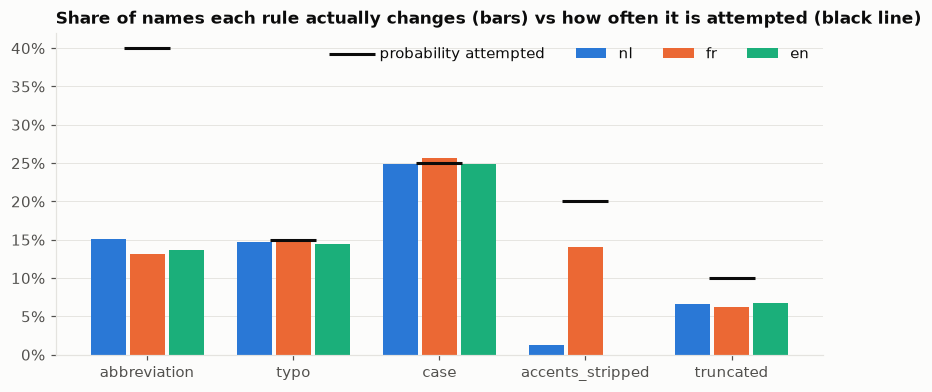

,abbreviation,typo,case,accents_stripped,truncated
language,,,,,
nl,15.1%,14.7%,24.8%,1.3%,6.6%
fr,13.1%,15.0%,25.7%,14.1%,6.2%
en,13.7%,14.5%,24.9%,0.0%,6.8%


In [4]:
runs = []
for lang in ["nl", "fr", "en"]:
    for a in chart:
        for seed in range(50):
            _, tags = apply_noise(a.name(lang), lang, Random(f"{a.code}-{lang}-{seed}"))
            runs.append({"language": lang, **{op: op in tags for op in NOISE_PROBS}, "n_tags": len(tags)})
runs = pd.DataFrame(runs)
changed = runs.groupby("language")[list(NOISE_PROBS)].mean().loc[["nl", "fr", "en"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(NOISE_PROBS))
width = 0.8 / 3
for i, lang in enumerate(changed.index):
    ax.bar(x + (i - 1) * width, changed.loc[lang], width * 0.9, color=LANGUAGE_COLORS[lang], label=lang)
ax.scatter(x, list(NOISE_PROBS.values()), marker="_", s=900, linewidths=2, color=INK, zorder=3, label="probability attempted")
ax.set_xticks(x, list(NOISE_PROBS))
ax.yaxis.set_major_formatter(pct())
ax.grid(axis="x", visible=False)
ax.set_title("Share of names each rule actually changes (bars) vs how often it is attempted (black line)")
ax.legend(ncols=4, loc="upper right")
plt.show()
display(changed.style.format("{:.1%}"))

How to read it: the black line is the setting, the bars are what happens. **typo** and **case** almost always land, because nearly every name has a long word and letters to change case. **abbreviation** lands well below its 40%, because many names have no dictionary word. **accents_stripped** never happens in English. That's why every row records the tags that *actually* changed it: results can later be split by real distortion, not by setting.

## 4. How messy a name gets

The number of rules that changed each name, over the same 28,500 runs. About half of the names come through unchanged, and only one in eight gets two or more distortions. That's realistic, because plenty of real accounts simply use the official name. The rule-based companies add other changes on top: sub-accounts, bilingual labels and unrelated account codes (notebook 03).

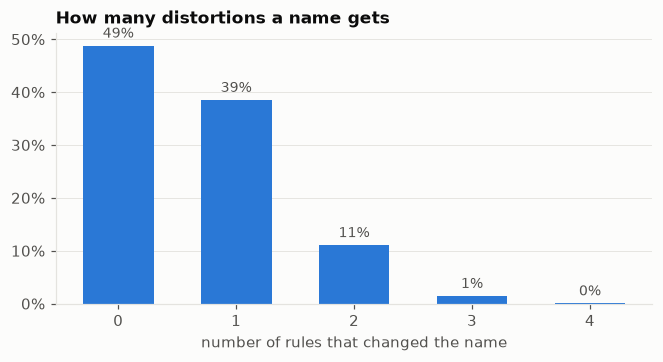

In [5]:
counts = runs["n_tags"].value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(counts.index.astype(str), counts.values, color=SINGLE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in counts.values], padding=3, fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(pct())
ax.grid(axis="x", visible=False)
ax.set_xlabel("number of rules that changed the name")
ax.set_title("How many distortions a name gets")
plt.show()

## 5. Real examples from the training data

Two rule-based training accounts per tag, next to the official name of their group, the one the mapper must find:

In [6]:
from d1.datagen.schema import read_jsonl
train = [r for r in read_jsonl(config.data.generated_dir / "train.jsonl") if r.source == "rules" and r.language != "mixed"]
examples = []
for op in NOISE_PROBS:
    picked = [r for r in train if r.noise == [op]][:2]  # only this one rule, so its effect is visible
    for r in picked:
        examples.append({"tag": op, "account name": r.name, "official name": by_code[r.target_code].name(r.language), "group": r.target_code})
display(pd.DataFrame(examples).set_index("tag"))

,account name,official name,group
tag,,,
abbreviation,Herwaarderingsmeerwaarden op fin. vaste activa,Herwaarderingsmeerwaarden op financiële vaste activa,122
abbreviation,Voorz. voor bel.,Voorzieningen voor belastingen,161
typo,Vooruitbetalingen op besellingen (> 1 jaar),Vooruitbetalingen op bestellingen (> 1 jaar),176
typo,Te betalne wissels,Te betalen wissels,441
case,achtergestelde leningen (> 1 jaar),Achtergestelde leningen (> 1 jaar),170
case,leasingschulden en soortgelijke schulden (> 1 jaar vervallend < 1 jaar),Leasingschulden en soortgelijke schulden (> 1 jaar vervallend < 1 jaar),422
accents_stripped,Frais d'etablissement,Frais d'établissement,200
accents_stripped,TVA a payer,TVA à payer,451
truncated,Participations dans les sociét,Participations dans les sociétés liées,280


## 6. What is *not* happening

- **No rewording.** The rules only abbreviate, cut, misspell and change case. They never say "wages" for "remuneration" or invent "Huur kantoor Gent" for "rent". That is what the LLM-written companies add (notebook 04), and notebook 08 shows those are much harder to map.
- **No randomness from outside.** Every random choice comes from the `Random` object passed in. The same seed always gives the same messy name, so all data can be rebuilt exactly.